Telecom Churn Dataset
## Classification


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/Telcom-Customer-Churn - Telcom-Customer-Churn (1).csv")

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.50,No


In [ ]:
# shape
df.shape

(7043, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df["TotalCharges"]=df["TotalCharges"].replace(" ",np.nan,inplace=True)



/tmp/ipykernel_1775/3745926474.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"]=df["TotalCharges"].replace(" ",np.nan,inplace=True)


In [ ]:
df["TotalCharges"] =pd.to_numeric(df["TotalCharges"],errors="coerce")

In [ ]:
#Duplicate Value
df.duplicated().sum()

np.int64(0)

In [ ]:
# Check Missing value

df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
print(df['TotalCharges'].isnull().sum())

7043


In [ ]:
# How to find missing value
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,NaN,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,NaN,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,NaN,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,NaN,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,NaN,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,NaN,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,NaN,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,NaN,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,NaN,Yes


<Axes: >

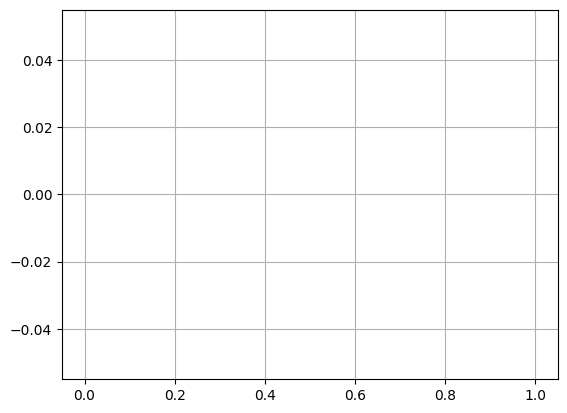

In [ ]:
df["TotalCharges"].hist()

<Axes: xlabel='MonthlyCharges'>

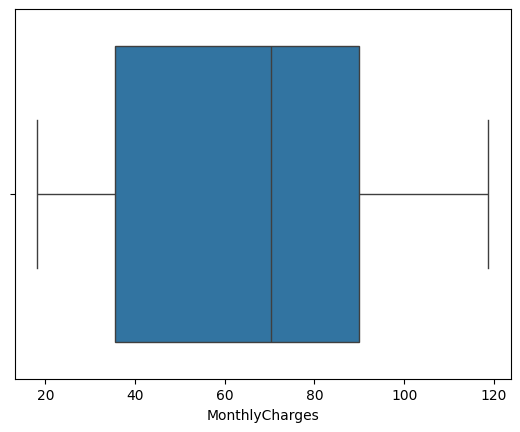

In [ ]:
sns.boxplot(x="MonthlyCharges",data =df)

In [ ]:
median=df["TotalCharges"].median()

In [ ]:
df["TotalCharges"]=df["TotalCharges"].fillna(median,inplace=True)

/tmp/ipykernel_1775/1246188675.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"]=df["TotalCharges"].fillna(median,inplace=True)


In [ ]:
# Numerical and categorical value

df_num=df.select_dtypes(["int64","float64"])
df_cat=df.select_dtypes("object")

df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,None,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,None,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,None,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),None,No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,None,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,None,No
7039,2234-XADUH,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),None,No
7040,4801-JZAZL,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,None,No
7041,8361-LTMKD,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,None,Yes


In [ ]:
df_num

,SeniorCitizen,tenure,MonthlyCharges
0,0,1,29.85
1,0,34,56.95
2,0,2,53.85
3,0,45,42.30
4,0,2,70.70
...,...,...,...
7038,0,24,84.80
7039,0,72,103.20
7040,0,11,29.60
7041,1,4,74.40


Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
le=LabelEncoder()

In [ ]:
#converting categorical into numeric value

for  i in df_cat:
  from sklearn.preprocessing import LabelEncoder
  le=LabelEncoder()
  df_cat[i]=le.fit_transform(df_cat[i])
  print(i)

customerID
gender
Partner
Dependents
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
TotalCharges
Churn


In [ ]:
df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
0,5375,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0,0
1,3962,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0,0
2,2564,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,0,1
3,5535,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0,0
4,6511,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,4853,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0,0
7039,1525,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0,0
7040,3367,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0,0
7041,5934,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,0,1


In [ ]:

print(df_cat.columns)

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')


In [ ]:
df_cat=df_cat.drop(columns="customerID")


In [ ]:

df_cat

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0,0
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0,0
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,0,1
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0,0
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0,0
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0,0
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0,0
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,0,1


In [ ]:
# combine the numacical nad categorial dataset
df_new=pd.concat([df_cat,df_num],axis=1)

df_new

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn,SeniorCitizen,tenure,MonthlyCharges
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0,0,0,1,29.85
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0,0,0,34,56.95
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,0,1,0,2,53.85
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0,0,0,45,42.30
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,0,1,0,2,70.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0,0,0,24,84.80
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0,0,0,72,103.20
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0,0,0,11,29.60
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,0,1,1,4,74.40


In [ ]:
# Independent and Dependant varivale

x=df_new.drop("Churn",axis=1)

y=df_new["Churn"]

In [ ]:
x

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,SeniorCitizen,tenure,MonthlyCharges
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0,0,1,29.85
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0,0,34,56.95
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,0,0,2,53.85
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0,0,45,42.30
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,0,0,2,70.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0,0,24,84.80
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0,0,72,103.20
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0,0,11,29.60
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,0,1,4,74.40


In [ ]:
y

,Churn
0,0
1,0
2,1
3,0
4,1
...,...
7038,0
7039,0
7040,0
7041,1


In [ ]:
#Splintting the datset into training and testing

from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

In [ ]:

print(x_train.shape,y_train.shape)

(4930, 19) (4930,)


In [ ]:

print(x_test.shape,y_test.shape)

(2113, 19) (2113,)


In [ ]:
# Scaling the number Min Max Scaler

from sklearn.preprocessing import MinMaxScaler


In [ ]:
mm=MinMaxScaler()

In [ ]:
x_train=mm.fit_transform(x_train)
x_test=mm.transform(x_test)

In [ ]:
x_train

array([[1.        , 1.        , 1.        , ..., 0.        , 0.75      ,
        0.52267065],
       [1.        , 0.        , 0.        , ..., 0.        , 0.01388889,
        0.62082711],
       [1.        , 0.        , 0.        , ..., 0.        , 0.18055556,
        0.01046338],
       ...,
       [1.        , 1.        , 1.        , ..., 0.        , 0.16666667,
        0.02889885],
       [1.        , 0.        , 0.        , ..., 1.        , 0.16666667,
        0.80916791],
       [1.        , 0.        , 0.        , ..., 0.        , 0.36111111,
        0.01544594]])

In [ ]:
x_test

array([[0.        , 1.        , 0.        , ..., 0.        , 0.01388889,
        0.06527155],
       [1.        , 0.        , 0.        , ..., 0.        , 0.56944444,
        0.06975585],
       [0.        , 1.        , 1.        , ..., 0.        , 0.72222222,
        0.01096163],
       ...,
       [1.        , 1.        , 1.        , ..., 0.        , 0.83333333,
        0.42102641],
       [1.        , 0.        , 0.        , ..., 0.        , 0.27777778,
        0.72197309],
       [1.        , 1.        , 1.        , ..., 0.        , 0.30555556,
        0.32735426]])

In [ ]:
# Apply Algorithm

df_new["Churn"].value_counts()

,count
Churn,
0,5174
1,1869


## Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lg=LogisticRegression(max_iter=1000)

In [ ]:
lg.fit(x_train,y_train)

y_pred=lg.predict(x_test)

In [ ]:
y_pred

array([1, 0, 0, ..., 0, 1, 0])

In [ ]:
pd.DataFrame({"Actual Value":y_test,"Predictive value":y_pred})

,Actual Value,Predictive value
185,1,1
2715,0,0
3825,0,0
1807,1,1
132,0,0
...,...,...
5522,1,1
6377,1,1
5500,0,0
2392,0,1


# Confusion Matrix-

A confusion matrix is used to evaluate the performance of a classification model, such as Logistic Regression

1 .Accuracy - How much % prdiction corect


2.Precision-- Out of all the observations predicted as Positive, how many are actually Positive?
"When the model says YES, how often is it correct

precision =Tp/Tp+FP


3.Recall- How many actual YES cases did model find?

=TP/TP+FN

4.F1_score--Balance between Precision & Recall

=2 x precision x Recall / Precision+ Recall

# **ROC**--Receiver Operating Characteristic.
  
**AUC**--Area under the curve

In [ ]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report

In [ ]:
Accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)
print("Accuracy_score",Accuracy)


Accuracy_score 0.8121154756270705


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8121154756270705
Precision: 0.6886993603411514
Recall: 0.5627177700348432
F1 Score: 0.6193672099712368


In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1539
           1       0.69      0.56      0.62       574

    accuracy                           0.81      2113
   macro avg       0.77      0.73      0.75      2113
weighted avg       0.80      0.81      0.81      2113



In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
confusion_matrix(y_test,y_pred)

array([[1393,  146],
       [ 251,  323]])

In [ ]:

! pip install imblearn

SMOTE Technique

ROC = Receiver Operating Characteristic

AUC = Area Under the Curve

1	Perfect model

0.9–1.0	Excellent

0.8–0.9	 very Good

0.7–0.8	Good

0.6–0.7	Work

0.5     Random Guessing

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
smote=SMOTE(random_state=42)


In [ ]:

x_train_resample,y_train_resample=smote.fit_resample(x_train,y_train)

In [ ]:
x_train_resample.shape,y_train_resample.shape

((7270, 19), (7270,))

In [ ]:
lg.fit(x_train_resample,y_train_resample)
y_pred=lg.predict(x_test)

In [ ]:
confusion_matrix(y_test,y_pred)

array([[1137,  402],
       [ 105,  469]])

In [ ]:
pd.DataFrame({"Actual value":y_test,"Predicted value":y_pred})

,Actual value,Predicted value
185,1,1
2715,0,0
3825,0,0
1807,1,1
132,0,0
...,...,...
5522,1,1
6377,1,1
5500,0,0
2392,0,1


In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.74      0.82      1539
           1       0.54      0.82      0.65       574

    accuracy                           0.76      2113
   macro avg       0.73      0.78      0.73      2113
weighted avg       0.81      0.76      0.77      2113



In [ ]:
from sklearn.metrics import roc_auc_score

In [ ]:
y_prob=lg.predict_proba(x_test)[:,1]

In [ ]:
y_prob

array([0.77349854, 0.20847778, 0.02163776, ..., 0.01692182, 0.81263454,
       0.38296815])

In [ ]:
roc_auc=roc_auc_score(y_test,y_prob)

In [ ]:
roc_auc

np.float64(0.8555308777816265)

<Axes: xlabel='Churn', ylabel='count'>

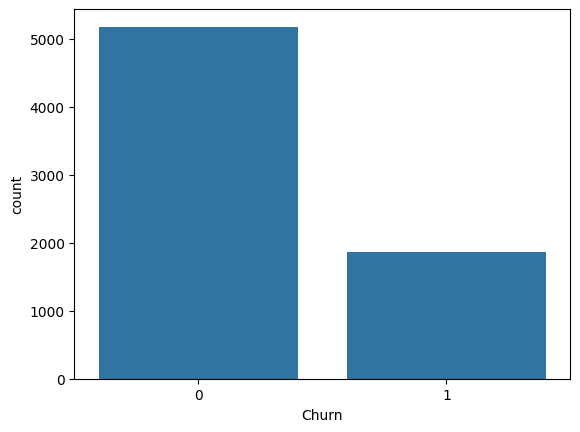

In [ ]:
sns.countplot(x="Churn",data=df_new)

Text(0.5, 1.0, 'Churn%')

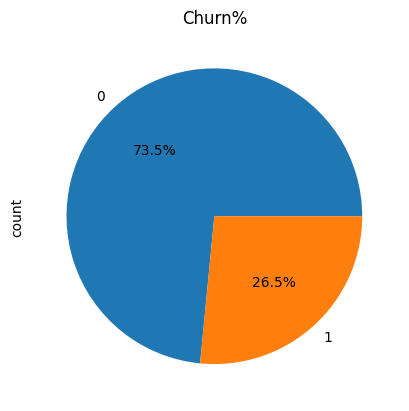

In [ ]:
df_new["Churn"].value_counts().plot.pie(autopct="%1.1f%%")
plt.title("Churn%")

## KNN

K-Nearest Neighbors--

K = number of nearest neighbors considered

KNN = Find → Nearest → Neighbors → Vote/Predic

For classification → majority vote

For regression → average of nearby values

how do we measure closeness--
Euclidean distance and  Manhattan distance

Decision Tree(Root Node,Decision Node) and

 pruning technique (Pruning means removing unnecessary branches from a Decision Tree. Pruning is the process of removing unnecessary branches from a Decision Tree to reduce overfitting and improve the model's ability to generalize to unseen data.

 1. Pre-Pruning--We stop the tree from growing too much.

 2. Post-Pruning--First, the tree is allowed to grow, and then unnecessary branches are removed



In [ ]:
# Decision Tree Algorithum

from sklearn.tree import DecisionTreeClassifier

In [ ]:
dc=DecisionTreeClassifier(random_state=42)

In [ ]:
dc.fit(x_train,y_train)
y_pred=dc.predict(x_test)

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1539
           1       0.48      0.49      0.48       574

    accuracy                           0.72      2113
   macro avg       0.64      0.65      0.65      2113
weighted avg       0.72      0.72      0.72      2113



In [ ]:
y_prob=dc.predict_proba(x_test)[:,1]

In [ ]:
roc_auc=roc_auc_score(y_test,y_prob)

In [ ]:
roc_auc

np.float64(0.6458213057485629)

In [ ]:
dc.score(x_train_resample,y_train_resample)

0.9046767537826685

In [ ]:
dc.score(x_test,y_test)

0.7179365830572646

In [ ]:
dc1=DecisionTreeClassifier(max_depth=2)

In [ ]:

dc1.fit(x_train_resample,y_train_resample)
y_pred_dc1=dc1.predict(x_test)

In [ ]:
print(classification_report(y_test,y_pred_dc1))

              precision    recall  f1-score   support

           0       0.88      0.74      0.80      1539
           1       0.51      0.73      0.60       574

    accuracy                           0.74      2113
   macro avg       0.70      0.74      0.70      2113
weighted avg       0.78      0.74      0.75      2113



In [ ]:
from sklearn.tree import plot_tree

[Text(0.5, 0.8333333333333334, '[1.         1.         1.         0.         0.5        0.\n 1.         1.         1.         1.         1.         1.\n 1.         1.         0.         0.         0.         1.\n 0.47234679] <= 0.5\ngini = 0.5\nsamples = 7270\nvalue = [3635, 3635]\nclass = No'),
 Text(0.25, 0.5, '[0.         0.         0.         1.         0.         0.5\n 1.         0.         0.         0.         1.         0.\n 0.5        1.         0.33333333 0.         0.         0.16666667\n 0.66666667] <= 0.499\ngini = 0.434\nsamples = 4878\nvalue = [1553, 3325]\nclass = Yes'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.371\nsamples = 3604\nvalue = [888, 2716]\nclass = Yes'),
 Text(0.375, 0.16666666666666666, 'gini = 0.499\nsamples = 1274\nvalue = [665, 609]\nclass = No'),
 Text(0.75, 0.5, '[0.         0.         1.         1.         0.         1.\n 0.5        0.5        0.5        0.5        0.5        0.5\n 1.         0.         

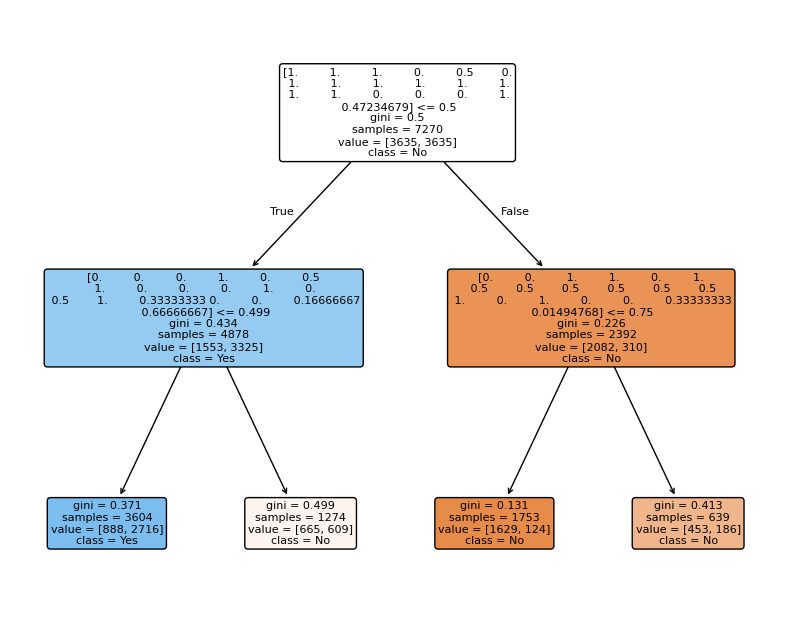

In [ ]:
plt.figure(figsize=(10,8))
plot_tree(
    dc1,
    feature_names=x_train_resample,
    class_names=["No","Yes"],
    filled=True,
    rounded=True,
    fontsize=8
    )

# Random Forest(wine Quality Prediction)--
Random Forest creates many Decision Trees and combines their predictions to get the final answer.

 Bagging--Bootstrap Aggregation

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf=RandomForestClassifier(n_estimators=100,random_state=42)


In [ ]:
rf.fit(x_train_resample,y_train_resample)

y_pred_rf=rf.predict(x_test)

In [ ]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1539
           1       0.60      0.58      0.59       574

    accuracy                           0.78      2113
   macro avg       0.72      0.72      0.72      2113
weighted avg       0.78      0.78      0.78      2113



In [ ]:
y_prob_rf=rf.predict_proba(x_test)[:,1]

In [ ]:
roc_auc_score(y_test,y_pred_rf)

np.float64(0.7168525423767187)

In [ ]:
confusion_matrix(y_test,y_pred_rf)

array([[1319,  220],
       [ 243,  331]])

# **SVM** (Support Vector Machine)
SVM finds the best decision boundary, called a hyperplane, that separates different classes of data

Hyperplane: The decision boundary that separates classes.

Support vectors: The data points closest to the decision boundary.

Margin: The distance between the decision boundary and the nearest data points from each class.

Maximum margin: SVM tries to find the boundary with the largest possible margin.

type of SVM--linear and Non-linear(2D to 3D)

In [ ]:
from sklearn.svm import SVC

In [ ]:
sv=SVC(kernel="rbf",random_state=42,probability=True)

In [ ]:
sv.fit(x_train_resample,y_train_resample)

y_pred_sv=sv.predict(x_test)

In [ ]:
print(classification_report(y_test,y_pred_sv))

              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1539
           1       0.55      0.72      0.62       574

    accuracy                           0.76      2113
   macro avg       0.71      0.75      0.72      2113
weighted avg       0.79      0.76      0.77      2113



In [ ]:
y_prob_sv=sv.predict_proba(x_test)[:,1]

In [ ]:
roc_auc_score(y_test,y_pred_sv)

np.float64(0.7465779398813203)

In [ ]:
confusion_matrix(y_test,y_pred_sv)

array([[1196,  343],
       [ 163,  411]])

# Model Evaluation Metrics

**Cross Validation Technique**---is a technique used in machine learning to evaluate a model's performance by dividing the dataset into multiple parts and training and testing the model on different parts.

1. K-Fold Cross-Validation--The dataset is divided into K equal (or nearly equal) folds. The model trains on K−1 folds and tests on the remaining fold. This repeats K times.

2. Stratified K-Fold--Maintains approximately the same proportion of each class in every fold.

Pipeline--Pipeline combines preprocessing and model training steps into a single workflow, helping simplify code and prevent data leakage.

Bias-Variance Tradeoff--diffrence bet actual value and predicted value

Overfitting: Performs very well on training data but poorly on unseen data.

Underfitting: Fails to learn the underlying patterns and performs poorly on both training and testing data.

High bias, low variance → underfitting

Low bias, high variance → overfitting

Balanced model Appropriate complexity → better generalization

High Bias = Underfitting = Too simple High Variance = Overfitting = Too complex

In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.model_selection import KFold,StratifiedKFold, cross_val_score

from sklearn.model_selection import cross_validate

In [ ]:
lg_pipeline= Pipeline([
    ("scaler",MinMaxScaler()),
    ("smote",SMOTE(random_state=42)),
    ("model",LogisticRegression(max_iter=1000))
])

In [ ]:
#cross validation

cv=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

In [ ]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression

In [ ]:
lg_pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))
])

In [ ]:
score = cross_validate(
    lg_pipeline,
    x_train,
    y_train,
    cv=cv,
    scoring=[
        "accuracy","precision","recall","f1","roc_auc"
    ],
    return_train_score=False
)

In [ ]:
score

{'fit_time': array([0.03103495, 0.04192424, 0.03587008, 0.03582811, 0.03804898]),
 'score_time': array([0.01778603, 0.04326963, 0.01744318, 0.01730704, 0.01720715]),
 'test_accuracy': array([0.72920892, 0.76064909, 0.73123732, 0.74239351, 0.76470588]),
 'test_precision': array([0.49014778, 0.52971576, 0.49246231, 0.50617284, 0.536     ]),
 'test_recall': array([0.76833977, 0.79150579, 0.75675676, 0.79150579, 0.77606178]),
 'test_f1': array([0.59849624, 0.63467492, 0.59665145, 0.61746988, 0.6340694 ]),
 'test_roc_auc': array([0.82204596, 0.84291503, 0.8224788 , 0.83423176, 0.85125576])}

In [ ]:
After_cv=pd.DataFrame({"Accuracy":score["test_accuracy"],
           "Precision": score["test_precision"],
           "recall" :score["test_recall"],
           "F1 Score" :score["test_f1"],
           "roc_auc" :score["test_roc_auc"]})

In [ ]:
After_cv.mean().round(3)

,0
Accuracy,0.746
Precision,0.511
recall,0.777
F1 Score,0.616
roc_auc,0.835


**Hyperparamter tunning Tecnique**--Hyperparameter tuning is the process of finding the best settings for a machine learning model to improve its performance and accuracy.

1. GridSearchCV--Tests all specified combinations of hyperparameter values and selects the best combination using cross-validation.

2.RandomizedSearchCV--Tests a random selection of combinations, which can save time when there are many hyperparameters.

In [ ]:
from sklearn.model_selection import GridSearchCV ,RandomizedSearchCV

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:

from sklearn.ensemble import RandomForestClassifier
#step 1--create pipeline

rf_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])



In [ ]:
#step 2-- define paramter grid
param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}



In [ ]:
#step 3--cross Validation


cv_rf=StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)





In [ ]:
#step 4--Hyperparamter Tunning

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    cv=cv_rf,
    scoring="f1",
    n_jobs=-1,
    return_train_score=False
)


In [ ]:
#step 5-- Training the dataset
grid_search_rf.fit(x_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', MinMaxScaler()),
                                       ('smote', SMOTE(random_state=42)),
                                       ('model',
                                        RandomForestClassifier(n_jobs=1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'model__criterion': ['gini', 'entropy'],
                         'model__max_depth': [5, 10, None],
                         'model__min_samples_leaf': [1, 2],
                         'model__min_samples_split': [2, 5],
                         'model__n_estimators': [100, 200]},
             scoring='f1')

In [ ]:
#step 6--Best Paramter
grid_search_rf.best_params_


{'model__criterion': 'gini',
 'model__max_depth': 10,
 'model__min_samples_leaf': 1,
 'model__min_samples_split': 2,
 'model__n_estimators': 100}

In [ ]:
best_estimator=grid_search_rf.best_estimator_

In [ ]:
y_pred_rf_et=best_estimator.predict(x_test)

y_pred_rf_et

array([1, 0, 0, ..., 0, 1, 0])

In [ ]:
confusion_matrix(y_test,y_pred_rf_et)

array([[1238,  301],
       [ 154,  420]])

In [ ]:
print(classification_report(y_test,y_pred_rf_et))

              precision    recall  f1-score   support

           0       0.89      0.80      0.84      1539
           1       0.58      0.73      0.65       574

    accuracy                           0.78      2113
   macro avg       0.74      0.77      0.75      2113
weighted avg       0.81      0.78      0.79      2113



**Bagging and Boosting Technique**

Bagging---(Random Forest,Bagging Classifier)Bagging is an ensemble technique that trains models independently on bootstrap samples and combines their predictions.(parallel)

Boosting technique--Boosting builds models sequentially, with each new model trying to improve on the errors of previous models.(sequential)

Boosting technique--
xGBoost, AdaBoost,Gradient Boost

In [ ]:
from sklearn.ensemble import (GradientBoostingClassifier,AdaBoostClassifier,BaggingClassifier,)

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score


In [ ]:
bagging_model=BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
    )

#Train
bagging_model.fit(x_train,y_train)

#Predict
y_pred_bagg=bagging_model.predict(x_test)
y_prob_bagg=bagging_model.predict_proba(x_test)[:,1]

#Evaluate
print("Bagging Accuracy:",accuracy_score(y_test,y_pred_bagg))
print(classification_report(y_test,y_pred_bagg))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_bagg))

Bagging Accuracy: 0.7884524372929484
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1539
           1       0.64      0.49      0.56       574

    accuracy                           0.79      2113
   macro avg       0.74      0.70      0.71      2113
weighted avg       0.78      0.79      0.78      2113

ROC-Auc: 0.8216679911160013


# **Apply Boosting**

**Adaboost**

In [ ]:
ada_boost=AdaBoostClassifier(
    estimator=RandomForestClassifier(random_state=42),
    n_estimators=200,
    random_state=42,
    learning_rate=1,
)

#Traing the model

ada_boost.fit(x_train,y_train)

#Prediction
y_pred_ada=ada_boost.predict(x_test)
y_prob_ada=ada_boost.predict_proba(x_test)[:,-1]

print("Boosting Accuracy:",accuracy_score(y_test,y_pred_ada))
print(classification_report(y_test,y_pred_ada))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_ada))

Boosting Accuracy: 0.7898722195929957
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      1539
           1       0.65      0.49      0.56       574

    accuracy                           0.79      2113
   macro avg       0.74      0.69      0.71      2113
weighted avg       0.78      0.79      0.78      2113

ROC-Auc: 0.7301955204180278



**Gradient Boost **

In [ ]:
#Apply Gradient Boosting

gradient_boost=GradientBoostingClassifier(
    n_estimators=200,
    random_state=42,
    max_depth=5,
    learning_rate=0.1,

)

#Training

gradient_boost.fit(x_train,y_train)

#Prediction
y_pred_gb=gradient_boost.predict(x_test)
y_prob_gb=gradient_boost.predict_proba(x_test)[:,-1]

#Evaluate
print("Gradient Boosting Accuracy:",accuracy_score(y_test,y_pred_gb))
print(classification_report(y_test,y_pred_gb))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_gb))


Gradient Boosting Accuracy: 0.7931850449597728
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1539
           1       0.65      0.53      0.58       574

    accuracy                           0.79      2113
   macro avg       0.74      0.71      0.72      2113
weighted avg       0.78      0.79      0.79      2113

ROC-Auc: 0.8397206883514114


**xGBoost**

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

xgb_boost = XGBClassifier(
    n_estimators=200,
    random_state=42,
    learning_rate=0.1,
    max_depth=5
)

#Training

xgb_boost.fit(x_train,y_train)

#Prediction
y_pred_xgb=xgb_boost.predict(x_test)
y_prob_xgb=xgb_boost.predict_proba(x_test)[:,-1]

#Evaluate
print("xgb Boosting Accuracy:",accuracy_score(y_test,y_pred_xgb))
print(classification_report(y_test,y_pred_xgb))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_xgb))

xgb Boosting Accuracy: 0.7979176526265973
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1539
           1       0.65      0.55      0.60       574

    accuracy                           0.80      2113
   macro avg       0.75      0.72      0.73      2113
weighted avg       0.79      0.80      0.79      2113

ROC-Auc: 0.8459337141408172


In [ ]:
from xgboost import XGBClassifier

xgb_boost = XGBClassifier(
    n_estimators=100,
    random_state=42,
    learning_rate=0.1,
    max_depth=5,
    eval_metric="logloss",        #parameter=eval_metric=logloss
)

#Training

xgb_boost.fit(x_train,y_train)

#Prediction
y_pred_xgb=xgb_boost.predict(x_test)
y_prob_xgb=xgb_boost.predict_proba(x_test)[:,-1]

#Evaluate
print("xgb Boosting Accuracy:",accuracy_score(y_test,y_pred_xgb))
print(classification_report(y_test,y_pred_xgb))
print("ROC-Auc:",roc_auc_score(y_test,y_prob_xgb))

xgb Boosting Accuracy: 0.8045433033601515
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1539
           1       0.67      0.54      0.60       574

    accuracy                           0.80      2113
   macro avg       0.76      0.72      0.74      2113
weighted avg       0.80      0.80      0.80      2113

ROC-Auc: 0.8518744920114198


#preprosssing step-----load the dataset

remove duplicate

missing value---
numrical--mean and median(skewness)(No-skewness)---Imputation technique
             ---categorical--mode---

check outlier----only numerical---lowerbound   upper bound

Encoding technique--numerical--

        categorical--label encoder

concat--all data num+categorical

scaling--1.standardization(Z-score)(-1 to 1)

2.MInMaxscaler(0-1)

